# AI Skills and Advertised Salaries | 2026 Job Market Study
### A reproducible Python portfolio case study · October 2026

**Research question:** Are AI-related skills associated with higher advertised salaries, and does the association survive observable job-market controls?

**Evidence, not causality.** This is a cross-sectional analysis of a selected ATS sample. The skill tags may be noisy, salary disclosure is incomplete, and seniority is not fully observed. Results describe *advertised* salaries, not actual earnings or changes over time.

**Data:** [Zalize tech job postings](https://huggingface.co/datasets/zalizedata/tech-job-postings-salary-dataset), configuration `S`. **License:** CC BY-NC 4.0; attribution required, commercial reuse restricted. Data is fetched when the notebook runs; raw data is not redistributed.

**Reproduction:** Python 3.10+; install packages from `requirements.txt`, then run all cells. Outputs are written to `outputs/`. First run requires internet.

## 1 · Environment and data acquisition

This notebook uses the `S` configuration for a fast, reproducible case study. The `S` sample is **not** the full dataset; do not generalize its percentages to the entire technology job market. The source may change between runs.

In [1]:
from pathlib import Path
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from IPython.display import display
from datasets import load_dataset, get_dataset_config_names

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 30)
OUTPUT = Path("outputs"); OUTPUT.mkdir(exist_ok=True)

In [2]:
from datasets import load_dataset, get_dataset_config_names
DATASET = "zalizedata/tech-job-postings-salary-dataset"
configs = get_dataset_config_names(DATASET)
print("Available configs:", configs)
config = next((x for x in configs if x.upper() == "S"), configs[0])
raw = load_dataset(DATASET, name=config, split="train").to_pandas()
print(f"Loaded {len(raw):,} rows and {raw.shape[1]} columns; config={config}")
display(raw.head(3))

Available configs: ['S', 'M', 'L']
Loaded 35,417 rows and 22 columns; config=S


,company_name,company_domain,company_industry,ats,ats_token,job_id,title,department,location_raw,country,city,is_remote,employment_type,salary_min,salary_max,salary_currency,salary_period,salary_from_text,skills,posted_at,scraped_at,url
0,1mind,1mind.com,None,ashby,1mind,46a3c257-5c87-4e8b-925a-8d5b332307d9,AI System Engineer,Engineering,Remote - US; San Francisco,United States,San Francisco,True,full_time,175000.0,250000.0,USD,year,False,"[kubernetes, llm, machine-learning, python, ty...",2026-05-14T12:55:35.891+00:00,2026-08-01T01:09:37Z,https://jobs.ashbyhq.com/1mind/46a3c257-5c87-4...
1,1mind,1mind.com,None,ashby,1mind,3d939e24-b792-4663-9ae2-9e4c468c127e,Prompting Implementation Specialist,Engineering,Remote - US,United States,None,True,full_time,80000.0,150000.0,USD,year,False,"[customer-success, data-science, llm, nlp, pyt...",2026-07-06T16:22:59.783+00:00,2026-08-01T01:09:37Z,https://jobs.ashbyhq.com/1mind/3d939e24-b792-4...
2,1mind,1mind.com,None,ashby,1mind,5a6b1b8f-7ad0-4afd-8916-538eb18627d9,Superhuman (Agent) Architect,Customer Success,Remote - US,United States,None,True,full_time,125000.0,220000.0,USD,year,False,"[javascript, llm, nlp, project-management, pyt...",2026-04-29T20:41:53.244+00:00,2026-08-01T01:09:37Z,https://jobs.ashbyhq.com/1mind/5a6b1b8f-7ad0-4...


## 2 · Data quality audit

We report missingness, duplicate posting identifiers, and raw salary values before filtering. A large row count does not guarantee representative salary data.

In [3]:
required = ["title", "skills", "salary_min", "salary_max", "salary_currency", "salary_period", "country"]
missing_cols = set(required) - set(raw.columns)
if missing_cols: raise ValueError(f"Source schema changed: {missing_cols}")
audit = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing_n": raw.isna().sum(), "missing_pct": (raw.isna().mean()*100).round(1)})
display(audit.sort_values("missing_pct", ascending=False))
print("Duplicate job IDs:", raw.duplicated(subset=[c for c in ["ats", "job_id"] if c in raw]).sum() if "job_id" in raw else "not available")
display(raw.groupby(["salary_currency", "salary_period"], dropna=False).size().sort_values(ascending=False).head(15))

,dtype,missing_n,missing_pct
company_industry,object,25160,71.0
company_domain,object,21575,60.9
salary_currency,object,21486,60.7
salary_period,object,21486,60.7
salary_min,float64,21486,60.7
salary_max,float64,21486,60.7
employment_type,object,9908,28.0
city,object,9565,27.0
department,object,5235,14.8
country,object,4975,14.0


Duplicate job IDs: 3741


salary_currency  salary_period
NaN              NaN              21486
USD              year             12030
                 hour               550
EUR              year               411
GBP              year               249
USD              month              233
CAD              year               191
EUR              month               77
PLN              year                29
INR              year                23
PLN              month               22
SGD              year                13
EUR              hour                 9
AUD              year                 9
CAD              hour                 8
dtype: int64

## 3 · Clean salary and skills data

To avoid mixing currencies or questionable exchange rates, restrict the salary comparison to USD-denominated postings. Convert annual, monthly, weekly and hourly posted ranges to annual equivalents (assumptions: 12 months, 52 weeks, 2,080 hours). These are standardization assumptions, **not** verified work schedules. We discard missing, inverted, zero or implausible salary ranges; the bounds are declared below and are sensitivity-tested later.

In [4]:
df = raw.copy()
if {"ats", "job_id"}.issubset(df.columns): df = df.drop_duplicates(["ats", "job_id"])
for c in ["salary_min", "salary_max"]: df[c] = pd.to_numeric(df[c], errors="coerce")
for c in ["salary_currency", "salary_period", "country", "title"]: df[c] = df[c].astype("string").str.strip()

def skill_list(x):
    if isinstance(x, (list, tuple, np.ndarray)): return [str(s).lower().strip() for s in x if s is not None]
    return []
df["skill_list"] = df["skills"].apply(skill_list)
AI_TERMS = {"artificial-intelligence", "artificial intelligence", "ai", "generative-ai", "generative ai", "genai", "llm", "llms", "large-language-models", "machine-learning", "machine learning", "deep-learning", "deep learning", "pytorch", "tensorflow", "langchain", "rag", "prompt-engineering", "openai"}
def is_ai(skills):
    return any((s in AI_TERMS or any(term in s for term in ["machine-learn", "generative-ai", "large-language-model", "deep-learn", "langchain"])) for s in skills)
df["ai_skill"] = df["skill_list"].apply(is_ai)
period = df["salary_period"].str.lower().str.replace(r"[^a-z]", "", regex=True)
factor = period.map({"year":1, "yearly":1, "annual":1, "annually":1, "month":12, "monthly":12, "week":52, "weekly":52, "hour":2080, "hourly":2080})
df["salary_low_usd"] = df["salary_min"] * factor
df["salary_high_usd"] = df["salary_max"] * factor
df["salary_mid_usd"] = (df["salary_low_usd"] + df["salary_high_usd"]) / 2
valid = (df["salary_currency"].str.upper().eq("USD").fillna(False) & factor.notna() & df["salary_low_usd"].between(20000, 700000) & df["salary_high_usd"].between(20000, 700000) & (df["salary_high_usd"] >= df["salary_low_usd"]))
paid = df.loc[valid].copy()
print(f"Original: {len(raw):,} | Deduplicated: {len(df):,} | Valid USD salary ranges: {len(paid):,} ({len(paid)/len(df):.1%})")
print("AI tagged share of all records:", f"{df.ai_skill.mean():.1%}")
print("AI tagged share with usable salary:", f"{paid.ai_skill.mean():.1%}" if len(paid) else "N/A")
if len(paid) < 100: warnings.warn("Few salary records; results may be unstable")

Original: 35,417 | Deduplicated: 31,676 | Valid USD salary ranges: 12,482 (39.4%)
AI tagged share of all records: 38.1%
AI tagged share with usable salary: 38.7%


## 4 · Hiring demand: roles, skills and AI prevalence

These percentages describe the **collected ATS postings**, not the entire labor market. Extracted skill tags may miss synonyms or skills described only in free text.

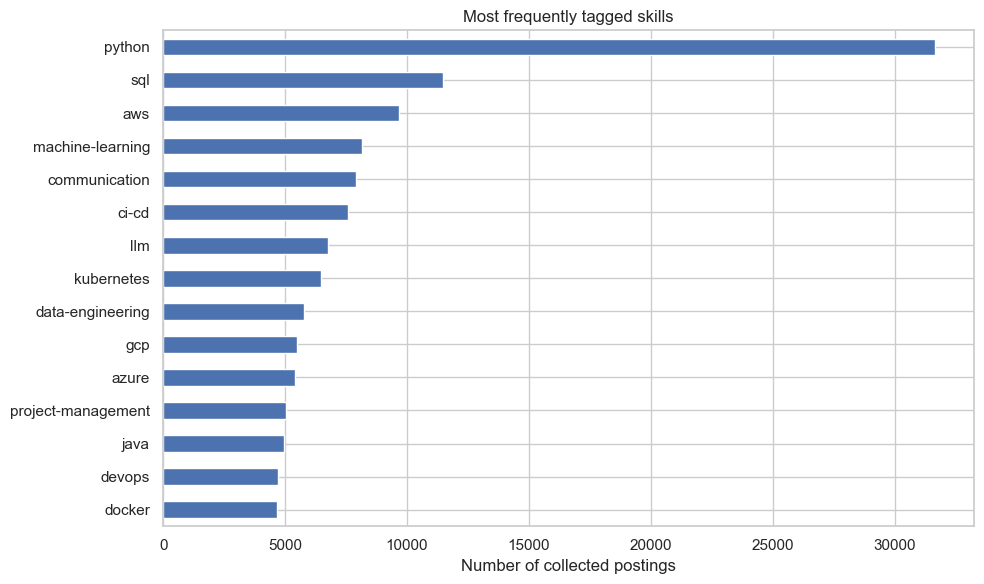

,postings
title,
Senior Software Engineer,288
Senior Data Engineer,197
Data Engineer,194
Software Engineer,186
Forward Deployed Engineer,167
Machine Learning Engineer,151
Senior Data Scientist,124
Data Scientist,120
AI Engineer,114


AI-tagged posting share: 38.1%


In [5]:
from collections import Counter
skill_counts = Counter(s for group in df.skill_list for s in set(group))
top = pd.Series(dict(skill_counts.most_common(15))).sort_values()
fig, ax = plt.subplots(figsize=(10, 6)); top.plot.barh(ax=ax)
ax.set(title="Most frequently tagged skills", xlabel="Number of collected postings", ylabel="")
plt.tight_layout(); fig.savefig(OUTPUT/"01_skill_demand.png", dpi=180); plt.show()
role_counts = df["title"].value_counts().head(15)
display(role_counts.rename("postings").to_frame())
print("AI-tagged posting share:", f"{df.ai_skill.mean():.1%}")

## 5 · Unadjusted salary gap

Compare median and mean salary midpoint by AI tag. The raw gap can reflect differences in role composition, country, seniority, salary disclosure and company mix—not necessarily an AI skill premium.

,count,mean,median,std
ai_skill,,,,
False,7653,175143.0,171500.0,56879.0
True,4829,201946.0,198500.0,66042.0


Unadjusted median AI/non-AI difference: +15.7%
Mann–Whitney U p-value: 2.153e-129


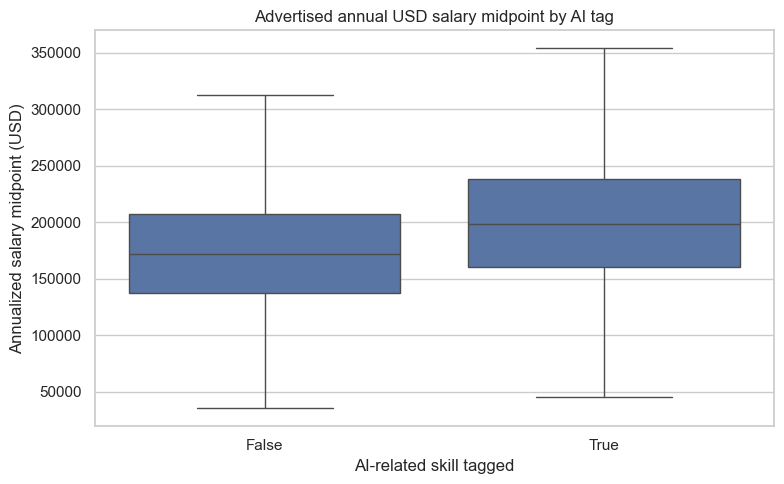

In [6]:
summary = paid.groupby("ai_skill").salary_mid_usd.agg(["count", "mean", "median", "std"])
display(summary.round(0))
if paid.ai_skill.nunique() == 2:
    a = paid.loc[paid.ai_skill, "salary_mid_usd"]
    b = paid.loc[~paid.ai_skill, "salary_mid_usd"]
    raw_gap = (a.median()/b.median()-1)*100
    print(f"Unadjusted median AI/non-AI difference: {raw_gap:+.1f}%")
    print("Mann–Whitney U p-value:", f"{stats.mannwhitneyu(a,b).pvalue:.4g}")
fig, ax = plt.subplots(figsize=(8,5))
sns.boxplot(data=paid, x="ai_skill", y="salary_mid_usd", showfliers=False, ax=ax)
ax.set(title="Advertised annual USD salary midpoint by AI tag", xlabel="AI-related skill tagged", ylabel="Annualized salary midpoint (USD)")
plt.tight_layout(); fig.savefig(OUTPUT/"02_salary_by_ai.png", dpi=180); plt.show()

## 6 · Correlation and role mix

Pearson correlation on binary AI tags is a point-biserial association; Spearman is a rank-based robustness view. Neither establishes causality.

In [7]:
if len(paid)>3 and paid.ai_skill.nunique()==2:
    r, p = stats.pointbiserialr(paid.ai_skill.astype(int), paid.salary_mid_usd)
    rho, ps = stats.spearmanr(paid.ai_skill.astype(int), paid.salary_mid_usd)
    print(f"Point-biserial r={r:.3f}, p={p:.3g}; Spearman rho={rho:.3f}, p={ps:.3g}")
role_field = "department" if "department" in paid.columns else "title"
role_mix = pd.crosstab(paid[role_field].fillna("Unknown"), paid.ai_skill, normalize="index")
role_mix["n"] = paid.groupby(paid[role_field].fillna("Unknown")).size()
display(role_mix.sort_values("n", ascending=False).head(15).round(3))

Point-biserial r=0.211, p=3.46e-125; Spearman rho=0.217, p=1.83e-132


ai_skill,False,True,n
department,,,
Engineering,0.553,0.447,2412
Software Engineering,0.694,0.306,324
Unknown,0.610,0.390,218
Technology,0.567,0.433,187
IT,0.636,0.364,162
Software,0.487,0.513,113
Engineering,0.740,0.260,104
Data,0.466,0.534,103
DV-Development,0.000,1.000,99


## 7 · Multivariable salary model

OLS models **log salary** with AI tag and fixed effects for country, job department and remote status. The AI coefficient is interpreted as an *adjusted association*, not a causal pay premium. To avoid extremely sparse categories, collapse rare groups into Other. HC3 heteroskedasticity-robust standard errors are used. Seniority is not directly controlled because it is not consistently available as a verified structured field in the inspected schema.

In [8]:
model_df = paid.copy()
model_df["log_salary"] = np.log(model_df.salary_mid_usd)
model_df["ai_flag"] = model_df.ai_skill.astype(int)
for source, dest in [("country","country_group"),("department","department_group")]:
    if source not in model_df: model_df[source] = "Unknown"
    s = model_df[source].fillna("Unknown").astype(str)
    common = s.value_counts().head(12).index
    model_df[dest] = s.where(s.isin(common), "Other")
model_df["remote_group"] = model_df["is_remote"].fillna(False).astype(str) if "is_remote" in model_df else "Unknown"
if len(model_df) >= 100 and model_df.ai_flag.nunique()==2:
    formula = "log_salary ~ ai_flag + C(country_group) + C(department_group) + C(remote_group)"
    fit = smf.ols(formula, data=model_df).fit(cov_type="HC3")
    beta = fit.params["ai_flag"]
    low, high = fit.conf_int().loc["ai_flag"]
    print(f"Adjusted AI-tag salary association: {100*np.expm1(beta):+.2f}%")
    print(f"95% CI: [{100*np.expm1(low):+.2f}%, {100*np.expm1(high):+.2f}%]")
    print(f"p={fit.pvalues['ai_flag']:.4g}; n={int(fit.nobs):,}; R²={fit.rsquared:.3f}")
    display(pd.DataFrame({"term":fit.params.index, "coefficient":fit.params.values, "p_value":fit.pvalues.values}).head(12))
else:
    fit = None
    print("Insufficient AI and non-AI salary records for a stable regression")

Adjusted AI-tag salary association: +15.01%
95% CI: [+13.61%, +16.42%]
p=7.77e-112; n=12,482; R²=0.159


,term,coefficient,p_value
0,Intercept,11.010206,0.000000e+00
1,C(country_group)[T.Brazil],-0.005628,9.537815e-01
2,C(country_group)[T.Canada],0.510580,3.427491e-18
3,C(country_group)[T.Chile],0.161742,3.215269e-02
4,C(country_group)[T.Colombia],0.176983,4.966644e-02
5,C(country_group)[T.Germany],0.356085,1.492679e-03
6,C(country_group)[T.India],-0.278548,7.949765e-02
7,C(country_group)[T.Mexico],0.100982,2.186353e-01
8,C(country_group)[T.Other],0.184689,4.774555e-03
9,C(country_group)[T.Turkey],0.014858,8.729085e-01


## 8 · Robustness and selection checks

Salary disclosure may differ between AI and non-AI jobs. Test whether the estimated association changes when trimming extreme salaries or focusing on the United States.

In [9]:
disclosure = df.groupby("ai_skill").apply(lambda g: valid.reindex(g.index).mean(), include_groups=False)
print("Usable USD salary share by AI tag:")
display(disclosure.rename("share").to_frame())
if fit is not None:
    trials=[]
    for label, subset in [("Baseline",model_df), ("Trim 1–99%", model_df[model_df.salary_mid_usd.between(*model_df.salary_mid_usd.quantile([.01,.99]).tolist())]), ("US only",model_df[model_df.country.astype("string").str.upper().isin(["US","USA","UNITED STATES","UNITED STATES OF AMERICA"])])]:
        if len(subset)<100 or subset.ai_flag.nunique()<2: continue
        try:
            f=smf.ols(formula, data=subset).fit(cov_type="HC3")
            trials.append({"sample":label,"n":len(subset),"adjusted_gap_pct":100*np.expm1(f.params["ai_flag"]),"p_value":f.pvalues["ai_flag"]})
        except Exception as e: print(label, str(e))
    robustness=pd.DataFrame(trials)
    display(robustness.round(3))
    robustness.to_csv(OUTPUT/"robustness.csv", index=False)

Usable USD salary share by AI tag:


,share
ai_skill,
False,0.390619
True,0.399619


,sample,n,adjusted_gap_pct,p_value
0,Baseline,12482,15.006,0.0
1,Trim 1–99%,12233,13.835,0.0
2,US only,9891,15.131,0.0


## 9 · Executive summary (generated from actual outputs)

The text below is computed only after the dataset loads. Use it in your GitHub README or LinkedIn post **after verifying the run**.

In [10]:
lines = [
    "# AI Skills & Salary Premium — Executive Brief",
    f"Dataset: DataForge / Zalize August 2026 ATS snapshot (config {config}); {len(df):,} deduplicated postings.",
    f"AI-tag prevalence: {df.ai_skill.mean():.1%} of collected postings.",
    f"Usable annualized USD salary ranges: {len(paid):,} ({len(paid)/len(df):.1%}).",
]
if len(paid) and paid.ai_skill.nunique()==2:
    lines.append(f"Raw median salary difference (AI vs non-AI): {raw_gap:+.1f}%.")
if fit is not None:
    lines.append(f"Adjusted association after country, department and remote controls: {100*np.expm1(beta):+.1f}% (95% CI {100*np.expm1(low):+.1f}% to {100*np.expm1(high):+.1f}%).")
lines.extend(["Interpretation: Correlation does not establish AI skills cause higher pay.",
              "Decision use: Compare skill demand and compensation by role before prioritizing training or hiring budgets.",
              "Limitations: Non-random ATS coverage; incomplete pay disclosure; inconsistent skills; no verified experience control; cross-sectional snapshot; USD-only salary comparison.",
              "Source: https://huggingface.co/datasets/zalizedata/tech-job-postings-salary-dataset (CC BY-NC 4.0)."])
brief="\n\n".join(lines)
print(brief)
(OUTPUT/"executive_brief.md").write_text(brief, encoding="utf-8")
summary.to_csv(OUTPUT/"salary_summary.csv")
print("Saved figures and outputs in:", OUTPUT.resolve())

# AI Skills & Salary Premium — Executive Brief

Dataset: DataForge / Zalize August 2026 ATS snapshot (config S); 31,676 deduplicated postings.

AI-tag prevalence: 38.1% of collected postings.

Usable annualized USD salary ranges: 12,482 (39.4%).

Raw median salary difference (AI vs non-AI): +15.7%.

Adjusted association after country, department and remote controls: +15.0% (95% CI +13.6% to +16.4%).

Interpretation: Correlation does not establish AI skills cause higher pay.

Decision use: Compare skill demand and compensation by role before prioritizing training or hiring budgets.

Limitations: Non-random ATS coverage; incomplete pay disclosure; inconsistent skills; no verified experience control; cross-sectional snapshot; USD-only salary comparison.

Source: https://huggingface.co/datasets/zalizedata/tech-job-postings-salary-dataset (CC BY-NC 4.0).
Saved figures and outputs in: /Users/tsov/Desktop/project 222/AI_Salary_GitHub_Project_FINAL/outputs


## 10 · Interview-ready discussion

**Why not claim AI increases salaries?** Because job role, seniority, company, region and unobserved factors may affect both skill requirements and pay. Controls reduce some confounding but do not establish causality.

**Why USD only?** To avoid invalid currency comparisons. This limits global representativeness.

**Why log salary?** It supports percentage-like coefficient interpretation and handles right-skewed compensation distributions.

**Why show missing salary coverage?** Published salary information may be systematically different from postings without salary ranges.

**What next?** Validate skill extraction against raw descriptions, collect longitudinal snapshots, build better seniority controls, and assess within-role/country matched comparisons.

## 11 · Focused GenAI sensitivity analysis

The broad AI indicator includes traditional machine learning frameworks. A narrower **GenAI** indicator tests whether conclusions depend on that choice. Skill lists are metadata tags, not verified proficiency. This section is an additional analysis; **its outputs must be rerun locally**.

In [11]:
GENAI_TERMS = {"generative-ai", "generative ai", "genai", "llm", "llms", "large-language-models", "langchain", "rag", "prompt-engineering", "openai"}
def has_genai(skills):
    return any(s in GENAI_TERMS or "generative-ai" in s or "large-language-model" in s for s in skills)
df["genai_skill"] = df["skill_list"].apply(has_genai)
paid["genai_skill"] = paid["skill_list"].apply(has_genai)
print(f"Narrow GenAI tags: {df.genai_skill.sum():,} / {len(df):,} ({df.genai_skill.mean():.1%})")
display(paid.groupby("genai_skill")["salary_mid_usd"].agg(["count","median","mean"]).round(0))
if paid.genai_skill.nunique() == 2:
    narrow = model_df.copy()
    narrow["genai_flag"] = paid.loc[narrow.index, "genai_skill"].astype(int)
    narrow_fit = smf.ols("log_salary ~ genai_flag + C(country_group) + C(department_group) + C(remote_group)", data=narrow).fit(cov_type="HC3")
    b = narrow_fit.params["genai_flag"]
    lo, hi = narrow_fit.conf_int().loc["genai_flag"]
    print(f"Narrow GenAI adjusted association: {100*np.expm1(b):+.1f}% (95% CI {100*np.expm1(lo):+.1f}% to {100*np.expm1(hi):+.1f}%)")

Narrow GenAI tags: 6,762 / 31,676 (21.3%)


,count,median,mean
genai_skill,,,
False,9925,177500.0,182016.0
True,2557,197500.0,199085.0


Narrow GenAI adjusted association: +10.5% (95% CI +8.9% to +12.1%)


## 12 · Within-title comparison (additional robustness)

Job titles provide a rough proxy for job type and seniority. Restrict to titles with at least 10 salary-observed postings and **both** AI and non-AI observations. This is a stronger like-for-like check than department alone, but titles remain inconsistent and employers may differ.

In [12]:
# Compare AI and non-AI postings within sufficiently represented job titles.
title_stats = model_df.groupby("title").agg(
    n=("ai_flag", "size"), ai_groups=("ai_flag", "nunique")
)
eligible_titles = title_stats.index[(title_stats.n >= 10) & (title_stats.ai_groups == 2)]
matched = model_df.loc[model_df["title"].isin(eligible_titles)].copy()
print(f"Eligible titles: {len(eligible_titles):,}; salary postings: {len(matched):,}")

if len(matched) >= 100 and matched["ai_flag"].nunique() == 2:
    for col in ["title", "country_group", "remote_group"]:
        matched[col] = matched[col].astype(str)
    title_fit = smf.ols(
        "log_salary ~ ai_flag + C(title) + C(country_group) + C(remote_group)",
        data=matched
    ).fit(cov_type="HC3")
    b = title_fit.params["ai_flag"]
    lo, hi = title_fit.conf_int().loc["ai_flag"]
    print(f"Within-title adjusted association: {100*np.expm1(b):+.1f}% "
          f"(95% CI {100*np.expm1(lo):+.1f}% to {100*np.expm1(hi):+.1f}%); "
          f"p={title_fit.pvalues['ai_flag']:.3g}; n={int(title_fit.nobs):,}")
else:
    print("Not enough comparable observations for a within-title regression.")


Eligible titles: 46; salary postings: 1,136
Within-title adjusted association: +2.5% (95% CI -0.5% to +5.7%); p=0.105; n=1,136


## 13 · Executive visuals and interpretation checklist

**How to read the findings:**

- The raw median gap compares two different groups of postings; it is **not** a raise a worker can expect from learning AI.
- The adjusted model controls for country, department, and remote status; unmeasured seniority, employer, and role specialization remain potential confounders.
- Statistical significance is not the same as causality or generalizability.
- The 2026 snapshot **cannot measure change over time**, hiring growth, or actual offers.
- Reconcile any differences between the broad AI tag, narrow GenAI tag, and within-title model before drawing business conclusions.

**Suggested interview discussion:** Explain the sample, the salary midpoint assumption, USD-only filtering, missing salary bias, why log-OLS was chosen, and what additional data would support causal or longitudinal claims.